# 02 - Return Prediction

Can trained models rank future returners better than simple behavioral rules?

In [1]:
from pathlib import Path
import sys

project_dir = Path.cwd()
if not (project_dir / "src" / "data_pipeline.py").exists():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))

## Build and check the cohort

In [2]:
from src.data_pipeline import run_pipeline

run_pipeline()

Saved 991,833 eligible users to data/processed/retention_cohort.parquet
Returned during days 15-44: 34,340 (3.5%)


In [3]:
import pandas as pd

cohort_path = project_dir / "data" / "processed" / "retention_cohort.parquet"
cohort = pd.read_parquet(cohort_path)
cohort.sort_values(["first_event_time", "user_id"]).head()

,user_id,first_event_time,events_first_14_days,active_days_first_14_days,high_intent_actions_first_14_days,days_since_last_event,events_days_7_13,events_per_active_day,longest_inactivity_gap_days,active_weeks_first_14_days,cart_actions_first_14_days,transactions_first_14_days,returned_days_15_44
796272,693516,2015-05-03 03:00:04.384000+00:00,3,1,2,13.99971,0,3.0,13.99971,1,2,0,0
483689,829044,2015-05-03 03:00:11.289000+00:00,1,1,0,14.00000,0,1.0,14.00000,1,0,0,0
692874,652699,2015-05-03 03:00:13.048000+00:00,1,1,0,14.00000,0,1.0,14.00000,1,0,0,0
134332,1125936,2015-05-03 03:00:24.154000+00:00,1,1,0,14.00000,0,1.0,14.00000,1,0,0,0
968236,1149227,2015-05-03 03:00:27.031000+00:00,1,1,0,14.00000,0,1.0,14.00000,1,0,0,0


In [4]:
from src.ranking import ALL_FEATURES, FEATURE_SETS, FEATURE_GROUPS, TARGET, split_cohort
assert cohort["user_id"].is_unique
assert cohort[ALL_FEATURES].notna().all().all()
assert cohort[TARGET].notna().all()
assert set(cohort[TARGET].unique()).issubset({0, 1})

print(f"Cohort: {len(cohort):,} visitors")
print(cohort[TARGET].value_counts().rename(index={0: "no return", 1: "returned"}))
print(f"Return rate: {cohort[TARGET].mean():.1%}")
train, validation, _, _ = split_cohort(cohort)

# Inspect feature-outcome relationships in training data only.
train.groupby(TARGET)[ALL_FEATURES].mean().T.rename(
    columns={0: "No return", 1: "Returned"}
)

Cohort: 991,833 visitors
returned_days_15_44
no return    957493
returned      34340
Name: count, dtype: int64
Return rate: 3.5%


returned_days_15_44,No return,Returned
events_first_14_days,1.815079,5.714625
active_days_first_14_days,1.102716,1.813837
cart_actions_first_14_days,0.041728,0.228200
transactions_first_14_days,0.012350,0.104592
days_since_last_event,13.629638,11.170383
events_per_active_day,1.560742,2.214751
events_days_7_13,0.055055,1.699612
longest_inactivity_gap_days,13.742118,12.241167
active_weeks_first_14_days,1.021489,1.212561
high_intent_actions_first_14_days,0.054077,0.332791


## Features

Summaries use training visitors only; all features stop before day 14. Groups cover volume, activity patterns, intent, and recency.

| Feature | Meaning at day 14 |
| --- | --- |
| Event count | Total recorded events. |
| Active days | Distinct UTC dates with activity; the rolling window can touch 15 dates. |
| Cart actions and transactions | Separate event counts. |
| Days since last event | Fractional days from the last event to day 14. |
| Events in days 7-13 | Events from day 7 up to, but excluding, day 14. |
| Events per active day | Event count divided by active UTC dates. |
| Longest inactivity gap | Longest gap between events, including the time from the last event to day 14. |
| Active weeks | Activity in one or both seven-day blocks. |

Correlated features are kept. Combined intent equals cart plus transaction counts, so it is used only for the simple ranking rule.

In [5]:
train[ALL_FEATURES].describe()

,events_first_14_days,active_days_first_14_days,cart_actions_first_14_days,transactions_first_14_days,days_since_last_event,events_per_active_day,events_days_7_13,longest_inactivity_gap_days,active_weeks_first_14_days,high_intent_actions_first_14_days
count,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000,169613.000000
mean,1.998844,1.136228,0.050515,0.016697,13.513746,1.591562,0.132555,13.671386,1.030493,0.067212
std,7.189532,0.577764,0.729867,0.426707,1.982874,2.011523,3.790169,1.285362,0.171940,1.091032
min,1.000000,1.000000,0.000000,0.000000,0.000006,1.000000,0.000000,0.977762,1.000000,0.000000
25%,1.000000,1.000000,0.000000,0.000000,13.999456,1.000000,0.000000,13.999456,1.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000,14.000000,1.000000,0.000000,14.000000,1.000000,0.000000
75%,2.000000,1.000000,0.000000,0.000000,14.000000,1.500000,0.000000,14.000000,1.000000,0.000000
max,1152.000000,15.000000,93.000000,61.000000,14.000000,128.000000,945.000000,14.000000,2.000000,152.000000


## Evaluation setup

Average precision (AP) selects the research ranking; capture measures the share of returners found at a fixed selection size.

| Stage | Visitors first observed (UTC) | Scoring / label availability |
| --- | --- | --- |
| Training | Through May 19, 00:00 | All outcomes known by July 3 |
| Validation | June 19 through June 23 | Scored July 3-7; outcomes known by August 8 |
| Final training | Through June 24, 00:00 | All outcomes known by August 8 |
| Later evaluation | July 25 onward, with complete follow-up | Scored from August 8 |

The intervening first-observed cohorts are excluded from the initial comparison because their labels are still maturing or their scoring dates fall outside validation. Final training recovers eligible earlier cohorts. The short log leaves only five validation scoring days; differences here may not persist in another period.

## Simple rules and full models

Compare four behavioral rules with logistic regression and XGBoost using all features. Recency ranks the most recently active visitors first.

In [6]:
from src.ranking import (
    RULES, rule_scores, ranking_metrics, evaluate_candidate, choose_ranking,
)

for name, rows in [("Training", train), ("Validation", validation)]:
    if rows.empty or rows[TARGET].nunique() < 2:
        raise ValueError(f"{name} data needs both outcomes.")

validation_predictions = rule_scores(validation)
validation_predictions.insert(0, "returned", validation[TARGET].to_numpy())
candidates = {}
metrics = {
    name: ranking_metrics(validation[TARGET], validation_predictions[name])
    for name in RULES
}


def compare_candidate(label, model_name, feature_set, params=None):
    predictions, result = evaluate_candidate(train, validation, model_name, feature_set, params)
    validation_predictions[label] = predictions
    metrics[label] = result
    candidates[label] = {
        "model": model_name, "feature_set": feature_set, "params": dict(params or {}),
    }


for model_name in ("logistic regression", "XGBoost"):
    compare_candidate(f"{model_name} / full", model_name, "full")

full_model_names = list(candidates)
print(f"Training visitors: {len(train):,}; validation visitors: {len(validation):,}")
print(f"Validation return rate: {validation[TARGET].mean():.1%}")
pd.DataFrame(metrics).T.style.format("{:.5f}")

Training visitors: 169,613; validation visitors: 46,854
Validation return rate: 3.6%


,average_precision,capture_at_5pct,capture_at_10pct,top_10_precision,capture_at_20pct
event count,0.06874,0.15178,0.22732,0.08220,0.36324
active days,0.07808,0.19106,0.27374,0.09898,0.35442
high intent,0.04022,0.07920,0.12767,0.04616,0.22458
recency,0.09841,0.21133,0.30460,0.11014,0.39728
logistic regression / full,0.11181,0.21429,0.29870,0.10800,0.40142
XGBoost / full,0.11646,0.21024,0.30667,0.11089,0.39939


## Remove one feature group at a time

Take the model with higher full-feature validation AP and refit it without each group, keeping its settings fixed.

Remove overlapping derived features with either parent group, as defined in `src/ranking.py`. Related information can still remain in other groups.

The AP change measures the group's added value for this model and setup, not causal importance.

In [7]:
ablation_model_label = max(full_model_names, key=lambda name: metrics[name]["average_precision"])
ablation_model = candidates[ablation_model_label]["model"]
full_ap = metrics[ablation_model_label]["average_precision"]
ablation_rows = {"full": {**metrics[ablation_model_label], "AP change vs full": 0.0}}

for group in FEATURE_GROUPS:
    feature_set = f"without {group}"
    label = f"{ablation_model} / {feature_set}"
    compare_candidate(label, ablation_model, feature_set)
    ablation_rows[feature_set] = {
        **metrics[label], "AP change vs full": metrics[label]["average_precision"] - full_ap,
    }

print(f"Group comparisons use: {ablation_model}")
pd.DataFrame(ablation_rows).T.style.format("{:.5f}")

Group comparisons use: XGBoost


,average_precision,capture_at_5pct,capture_at_10pct,top_10_precision,capture_at_20pct,AP change vs full
full,0.11646,0.21024,0.30667,0.11089,0.39939,0.00000
without activity volume,0.11457,0.20973,0.30197,0.10919,0.39979,-0.00188
without activity patterns,0.11266,0.20956,0.30661,0.11086,0.40020,-0.00380
without intent,0.11604,0.21138,0.30691,0.11097,0.40023,-0.00042
without recency,0.09239,0.18958,0.29576,0.10694,0.39348,-0.02406


## Small tuning search

Tune each algorithm's best tested feature set with two logistic-regression regularization values and three XGBoost changes. Defaults remain eligible. Only the stronger full-feature algorithm receives ablations, so logistic regression tunes full features in this run.

In [8]:
settings_to_try = {
    "logistic regression": [{"C": 0.1}, {"C": 10.0}],
    "XGBoost": [{"max_depth": 2}, {"max_depth": 4}, {"n_estimators": 200}],
}
# Choose feature sets before tuning either algorithm.
best_before_tuning = {}
for model_name in settings_to_try:
    names = [name for name, spec in candidates.items() if spec["model"] == model_name]
    best_before_tuning[model_name] = max(names, key=lambda name: metrics[name]["average_precision"])

tuning_rows = {}
for model_name, settings in settings_to_try.items():
    original = best_before_tuning[model_name]
    feature_set = candidates[original]["feature_set"]
    tuning_rows[original] = metrics[original]
    for params in settings:
        setting_name = ", ".join(f"{key}={value}" for key, value in params.items())
        label = f"{model_name} / {feature_set} / {setting_name}"
        compare_candidate(label, model_name, feature_set, params)
        tuning_rows[label] = metrics[label]

pd.DataFrame(tuning_rows).T.style.format("{:.5f}")

,average_precision,capture_at_5pct,capture_at_10pct,top_10_precision,capture_at_20pct
logistic regression / full,0.11181,0.21429,0.29870,0.10800,0.40142
logistic regression / full / C=0.1,0.11181,0.21429,0.29870,0.10800,0.40142
logistic regression / full / C=10.0,0.11181,0.21429,0.29870,0.10800,0.40142
XGBoost / full,0.11646,0.21024,0.30667,0.11089,0.39939
XGBoost / full / max_depth=2,0.11607,0.21453,0.30577,0.11056,0.40005
XGBoost / full / max_depth=4,0.11671,0.20838,0.30618,0.11071,0.40191
XGBoost / full / n_estimators=200,0.11666,0.20897,0.30627,0.11074,0.40300


## Validation gains

Compare the four rules with the best tested version of each algorithm. The left panel shows 0-20% selected; the right shows the full curve. The diagonal represents random selection.

The curves and tables use the same selection counts and average over ties at the cutoff.

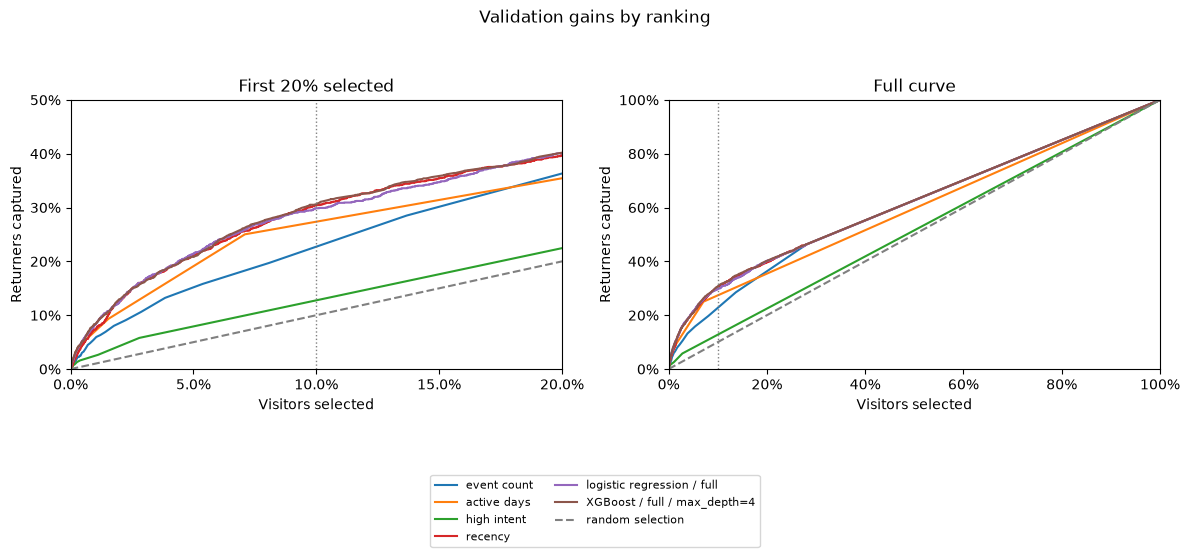

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


def plot_gains(scores, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
    capture_at_capacity = {}
    for name in scores.columns.drop("returned"):
        # Group equal scores so their row order cannot affect the curve.
        groups = scores.groupby(name)["returned"].agg(["size", "sum"])
        groups = groups.sort_index(ascending=False)
        selected = np.r_[0, groups["size"].cumsum().to_numpy() / len(scores)]
        captured = np.r_[0, groups["sum"].cumsum().to_numpy() / scores["returned"].sum()]
        for ax in axes:
            ax.plot(selected, captured, label=name)
        # Match the rounded-down visitor counts used in the metric tables.
        counts = np.maximum(1, (np.array([0.05, 0.10, 0.20]) * len(scores)).astype(int))
        capture_at_capacity[name] = np.interp(counts / len(scores), selected, captured)

    for ax in axes:
        ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="random selection")
        ax.axvline(0.10, color="gray", linestyle=":", linewidth=1)
        ax.set(xlabel="Visitors selected", ylabel="Returners captured")
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.yaxis.set_major_formatter(PercentFormatter(1))

    zoom_top = max(values[-1] for values in capture_at_capacity.values())
    zoom_top = min(1, np.ceil((zoom_top + 0.02) * 10) / 10)
    axes[0].set(xlim=(0, 0.20), ylim=(0, zoom_top), title="First 20% selected")
    axes[0].set_xticks([0, 0.05, 0.10, 0.15, 0.20])
    axes[1].set(xlim=(0, 1), ylim=(0, 1), title="Full curve")
    fig.suptitle(title)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=8)
    fig.tight_layout(rect=(0, 0.22, 1, 0.94))
    plt.show()


# Plot each simple rule and the best tested version of each algorithm.
validation_metrics = pd.DataFrame(metrics).T
chart_names = list(RULES)
for model_name in ("logistic regression", "XGBoost"):
    names = [name for name, spec in candidates.items() if spec["model"] == model_name]
    chart_names.append(validation_metrics.loc[names, "average_precision"].idxmax())
plot_gains(validation_predictions[["returned", *chart_names]], "Validation gains by ranking")

## Choose by validation AP

In [10]:
selected_name, chosen = choose_ranking(metrics, candidates)
selected_model = chosen["model"]
selected_feature_set = chosen["feature_set"]
selected_params = chosen["params"]

print(f"Chosen by validation AP: {selected_name}")
print(f"Features: {selected_feature_set}; settings: {selected_params or 'defaults'}")
validation_metrics.sort_values("average_precision", ascending=False).style.format("{:.5f}")

Chosen by validation AP: XGBoost / full / max_depth=4
Features: full; settings: {'max_depth': 4}


,average_precision,capture_at_5pct,capture_at_10pct,top_10_precision,capture_at_20pct
XGBoost / full / max_depth=4,0.11671,0.20838,0.30618,0.11071,0.40191
XGBoost / full / n_estimators=200,0.11666,0.20897,0.30627,0.11074,0.40300
XGBoost / full,0.11646,0.21024,0.30667,0.11089,0.39939
XGBoost / full / max_depth=2,0.11607,0.21453,0.30577,0.11056,0.40005
XGBoost / without intent,0.11604,0.21138,0.30691,0.11097,0.40023
XGBoost / without activity volume,0.11457,0.20973,0.30197,0.10919,0.39979
XGBoost / without activity patterns,0.11266,0.20956,0.30661,0.11086,0.40020
logistic regression / full,0.11181,0.21429,0.29870,0.10800,0.40142
logistic regression / full / C=0.1,0.11181,0.21429,0.29870,0.10800,0.40142
logistic regression / full / C=10.0,0.11181,0.21429,0.29870,0.10800,0.40142


## Save validation scores for the optional campaign notebook

Export scores with the selected model, features, and parameters. Rerun this step after changing the analysis or data.

In [11]:
from src.provenance import save_validation_scores

validation_export = validation[["user_id", "first_event_time"]].reset_index(drop=True).copy()
validation_export["returned"] = validation[TARGET].to_numpy()
validation_export["score"] = validation_predictions[selected_name].to_numpy()
validation_export["ranking"] = selected_name

export_path = project_dir / "data" / "processed" / "validation_scores.parquet"
save_validation_scores(validation_export, export_path, chosen)
print("Saved validation scores and model configuration to data/processed/")

Saved validation scores and model configuration to data/processed/


## Additional holdout evaluation

Refit the chosen model with its selected features and settings, using labels available by August 8. Compare it with the four rules on the later period.

This previously inspected holdout provides an additional chronological evaluation.

In [12]:
from src.evaluate_holdout import evaluate_holdout

results = evaluate_holdout(cohort, selected_model, selected_feature_set, selected_params)
print(f"Chosen model: {results['selected_model']}; features: {results['feature_set']}")
print(f"Settings: {results['params'] or 'defaults'}")
print(f"Final training visitors: {results['final_train_users']:,}")
print(f"Holdout visitors: {results['test_users']:,}; return rate: {results['return_rate']:.1%}")
results["metrics"].style.format("{:.5f}")

Chosen model: XGBoost; features: full
Settings: {'max_depth': 4}
Final training visitors: 538,406
Holdout visitors: 114,973; return rate: 2.7%


,average_precision,capture_at_5pct,capture_at_10pct,top_10_precision,capture_at_20pct
event count,0.05413,0.14609,0.23347,0.06313,0.37624
active days,0.07250,0.21775,0.28715,0.07765,0.36635
high intent,0.03005,0.07277,0.12158,0.03288,0.21918
recency,0.08690,0.23512,0.31071,0.08402,0.40495
XGBoost / full,0.10317,0.23738,0.31150,0.08424,0.40844


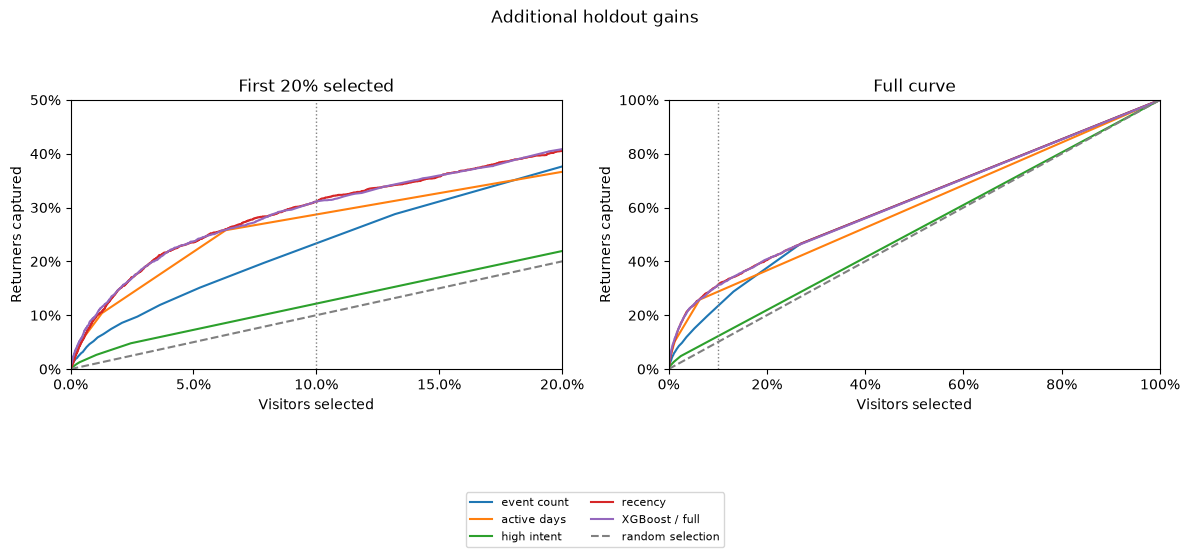

In [13]:
plot_gains(results["holdout_scores"], "Additional holdout gains")

## Interpretation

At 10% capacity, I would start with recency. It captures 31.1% of holdout returners versus 31.2% for XGBoost; the bootstrap below checks how uncertain that difference is. Higher AP alone does not justify the extra model maintenance for this use.

Removing recency and related features causes the largest ablation loss; intent and tuning add little. The next question is whether outreach changes returns.

## How uncertain is the gain over recency?

Resample holdout visitors 500 times, keeping each visitor's label and both scores together. Report percentile intervals for selected-ranking minus recency: absolute AP differences and capture differences in percentage points (pp). The intervals condition on fixed predictions in this period and omit training, selection, and time-drift uncertainty.

In [14]:
from src.ranking import paired_bootstrap

holdout_scores = results["holdout_scores"]
comparison_name = (selected_model if selected_model in RULES
                   else f"{selected_model} / {selected_feature_set}")
uncertainty = paired_bootstrap(
    holdout_scores["returned"], holdout_scores[comparison_name], holdout_scores["recency"],
)
print(f"{comparison_name} minus recency; 500 paired visitor resamples")
uncertainty_display = uncertainty.copy()
uncertainty_display.loc[uncertainty_display.index != "average_precision"] *= 100
uncertainty_display = uncertainty_display.rename(index={
    "average_precision": "AP (absolute)",
    "capture_at_5pct": "Capture at 5% (pp)",
    "capture_at_10pct": "Capture at 10% (pp)",
    "capture_at_20pct": "Capture at 20% (pp)",
})
uncertainty_display.style.format("{:+.5f}")

XGBoost / full minus recency; 500 paired visitor resamples


,difference,lower 95% bound,upper 95% bound
AP (absolute),+0.01627,+0.01084,+0.02193
Capture at 5% (pp),+0.22515,-0.19287,+0.59841
Capture at 10% (pp),+0.07917,-0.49073,+0.47443
Capture at 20% (pp),+0.34915,-0.11735,+0.81388
